In [1]:
print("200")

200


In [19]:
#basic deep agent
import os 
from dotenv import load_dotenv
from pathlib import Path


def load_agent_guidance() -> str:
    guidance_paths = (
        Path("projects") / "Agents.md",
        Path("deepagentdemo") / "projects" / "Agents.md",
    )
    for guidance_path in guidance_paths:
        if guidance_path.is_file():
            return guidance_path.read_text(encoding="utf-8")
    raise FileNotFoundError(
        "Could not locate deepagentdemo/projects/Agents.md. "
        "Run the notebook from the repository root or deepagentdemo directory."
    )
load_dotenv()

True

In [20]:
OPENAI_API_KEY= os.getenv("OPENAI_API_KEY")
# GROQ_API_KEY = os.getenv("GROQ_API_KEY")
# TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")

In [21]:
from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-4")
model

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4', 'langchain-openai': '1.7.0'}}, profile={'name': 'GPT-4', 'status': 'deprecated', 'release_date': '2023-11-06', 'last_updated': '2024-04-09', 'open_weights': False, 'max_input_tokens': 8192, 'max_output_tokens': 8192, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': False, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x0000027B26E4EA50>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x0000027B26E4F0E0>, root_client=<openai.OpenAI object at 0x

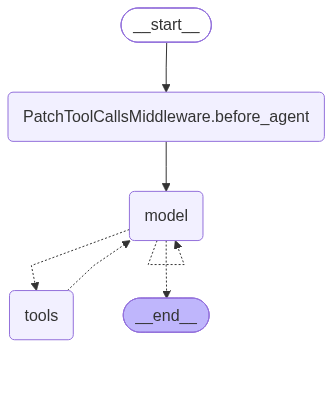

In [22]:
# Input Context
from deepagents import create_deep_agent

agent = create_deep_agent(
    model = "openai:gpt-4",
    system_prompt=f"{load_agent_guidance()}\n\nyou are a research assistant specializing in scientific literature,\nalways cite sources. use subagents for parallel research on different subtopics",


)
agent


In [24]:
#invoke the agent
results = agent.invoke({"messages":[{"role":"user","content":"What is deep agent in langchain"}]})
results

{'messages': [HumanMessage(content='What is deep agent in langchain', additional_kwargs={}, response_metadata={}, id='618dca34-50e3-4b4f-9c52-5a27dda7cb09'),
  AIMessage(content=[{'type': 'text', 'text': 'Deep agent in Langchain is a type of assistant that is trained on a broad and comprehensive base of knowledge. It has capabilities to extract precise information and answer a wide array of factual questions across different topics. Deep agents are not limited to merely answering questions, however, and can generate high quality and advanced output such as writing essays, articles, providing detailed steps on specific tasks, and more. \n\nThe depth and breadth of the deep agent\'s knowledge come from extensive training on a diverse range of data, including books, articles, websites, and other forms of information. This allows the deep agent to have a good grasp of a plethora of topics, making it a versatile digital assistant that can cater to varying user needs.\n\nHowever, please note

## Using **Agents.MD** for Context Enginnering 

In [25]:
from pathlib import Path
agents_md = Path("projects/Agents.md").read_text(encoding="utf-8")
agents_md

"# Deep Agents Project Guidance\n\nThis file is loaded as part of the system prompt whenever an agent is created\nin the demo notebooks. Keep these notes factual and relevant to this project.\n\n## Architecture\n\n- Deep Agents are built on LangGraph. `create_deep_agent` assembles a graph\n  around the selected chat model, tools, system prompt, middleware, and\n  configured state backend.\n- The model chooses actions, while tools define what the agent can actually do.\n  Only rely on tools that are provided to the agent or enabled by its\n  configuration.\n- Deep Agents commonly include planning, filesystem, and subagent capabilities\n  through middleware. Their exact availability and behavior depend on the\n  installed Deep Agents version and the graph configuration.\n- A backend determines how agent files are accessed and stored. For example,\n  a state backend scopes files to graph state, a filesystem backend works with\n  disk, and a store backend uses a LangGraph store. Do not ass

In [26]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer = MemorySaver()

In [27]:
agent = create_deep_agent(
    model = "openai:gpt-4",
checkpointer=MemorySaver()
#no backend no memory
)

In [30]:

result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": f"Here is our project guide:\n{agents_md}\nNow, who are you and what should you follow?"
            }
        ]
    },
    config={"configurable": {"thread_id": "demo_01"}}
)

print(result["messages"][-1].content)


[{'type': 'text', 'text': "I am an AI assistant designed to help users navigate systems, solve problems, and complete tasks. Given the context of this project, here are some key points I should follow:\n\n1. **Understand the agent architecture**: Deep Agents rely on LangGraph and combine different components like chat models, tools, system prompts, middleware, and a backend for state management. I should familiarize myself with these entities and their roles.\n\n2. **Use the right tools**: I should only rely on and use the tools provided to me or those enabled in my configuration. \n\n3. **Acknowledge the role of middleware**: I should understand that planning, filesystem, and subagent capabilities are often made possible through middleware. However, their availability and exact functionality depend on the Deep Agents version and the graph configuration.\n\n4. **Recognize the effect of backends**: Different backends can affect how files are accessed and stored. I should be aware of the

# Skills

In [38]:

from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

In [39]:
checkpointer = MemorySaver()
backend = StateBackend()

In [43]:
from pathlib import Path

#load the skills 
skills_content= Path("skills/langgraph-development/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph-development/SKILL.md": create_file_data(skills_content),
}


In [44]:
skills_files

{'/skills/langgraph-development/SKILL.md': {'content': '---\nname: langgraph-development\ndescription: Build, explain, review, or debug LangGraph and Deep Agents workflows, including state, nodes, edges, tools, persistence, and streaming. Use for LangGraph-specific agent orchestration work.\n---\n\n# LangGraph Development\n\nBuild workflows whose state, control flow, and tool permissions are explicit and testable.\n\n- Confirm the installed APIs and the current graph structure before proposing code.\n- Model durable state separately from transient runtime data.\n- Keep nodes focused, make routing conditions explicit, and design for retries or failures where external work occurs.\n- Only claim an agent can call tools, persist data, or delegate when those capabilities are configured.\n\nRead [instruction.md](instruction.md) for graph-design guidance. Read [examples.md](examples.md) for state and routing patterns.\n',
  'encoding': 'utf-8',
  'created_at': '2026-10-12T08:08:39.481431+00:0

In [47]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph-development", "python-development", "aws-development", "report-writing"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [48]:
skills_files

{'/skills/langgraph-development/SKILL.md': {'content': '---\nname: langgraph-development\ndescription: Build, explain, review, or debug LangGraph and Deep Agents workflows, including state, nodes, edges, tools, persistence, and streaming. Use for LangGraph-specific agent orchestration work.\n---\n\n# LangGraph Development\n\nBuild workflows whose state, control flow, and tool permissions are explicit and testable.\n\n- Confirm the installed APIs and the current graph structure before proposing code.\n- Model durable state separately from transient runtime data.\n- Keep nodes focused, make routing conditions explicit, and design for retries or failures where external work occurs.\n- Only claim an agent can call tools, persist data, or delegate when those capabilities are configured.\n\nRead [instruction.md](instruction.md) for graph-design guidance. Read [examples.md](examples.md) for state and routing patterns.\n',
  'encoding': 'utf-8',
  'created_at': '2026-10-12T08:10:12.547420+00:0

In [49]:
#create a chat model
from langchain.chat_models import init_chat_model

model = init_chat_model("groq:openai/gpt-oss-20b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000027B3038F4D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000027B305102F0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [63]:
agent=create_deep_agent(
    model="openai:gpt-4",
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

In [51]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)

Below is a quick‑reference of the skills that are available to me on this machine, along with the situations in which each one is the right tool to use.

| Skill | What it does | When to use it |
|-------|--------------|----------------|
| **aws‑development** | Design, implement, review, or troubleshoot AWS integrations and infrastructure. Handles IAM, security, cost‑management, observability, deployment safety, and other AWS‑specific concerns. | • You’re building or refactoring an AWS‑based service (EC2, Lambda, S3, DynamoDB, etc.).<br>• You need to audit IAM policies, set up monitoring, or optimize costs.<br>• You’re troubleshooting an AWS deployment or need guidance on best‑practice architecture. |
| **langgraph‑development** | Create, explain, review, or debug LangGraph and Deep Agents workflows (nodes, edges, state, persistence, streaming). | • You’re building or maintaining a LangGraph workflow.<br>• You need to understand how state flows through a graph, or why a particular node

In [53]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Explain conditional routing in LangGraph with a minimal example."
            }
        ],
        "files": skills_files
    },
    config={"configurable": {"thread_id": "skills-demo-2"}}
)

print(result["messages"][-1].content)

**Conditional routing in LangGraph**  
A *router* node decides which downstream node a message should go to based on the current graph state (or the incoming message).  The router’s decision is expressed as a *condition* – a Python function that returns the name of the next node.  This makes the control‑flow explicit, testable, and easy to reason about.

Below is a **minimal, runnable example** that shows:

1. A simple graph with three nodes:  
   * `greet` – replies with a greeting.  
   * `ask_weather` – asks for the user’s city.  
   * `weather` – returns a weather string (mocked).  
2. A **router** that looks at the user’s last message and routes to either `greet` or `ask_weather`.  
3. A tiny in‑memory **state store** (the “memory”) that keeps the conversation context.

```python
# minimal_langgraph.py
from typing import Dict, Any
from langgraph.graph import StateGraph, START, END
from langgraph.graph import State, add_messages, add_state
from langgraph.prebuilt import tools
from 

In [54]:
result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "How do i setup a EC2 instance in aws?"
            }
        ],
        "files": skills_files
    },
    config={"configurable": {"thread_id": "skills-demo-3"}}
)

print(result["messages"][-1].content)

**How to launch an EC2 instance in AWS**

Below is a concise, step‑by‑step guide that covers the most common path (the AWS Management Console) and an alternative using the AWS CLI.  
Feel free to skip the CLI part if you’re comfortable with the console, or use both for a deeper understanding.

---

## 1. Prerequisites

| Item | Why it matters | How to set it up |
|------|----------------|------------------|
| **AWS account** | You need an account to create resources. | Sign up at https://aws.amazon.com/ |
| **AWS CLI (optional)** | CLI lets you script or automate instance creation. | `pip install awscli` → `aws configure` (set `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`, `region`) |
| **IAM permissions** | Least‑privilege is key. | Create a user/role with `AmazonEC2FullAccess` (or a custom policy that allows `ec2:*`, `ec2:Describe*`, `ec2:CreateTags`) |
| **Region** | Cost and latency vary by region. | Pick a region close to your users (e.g., `us-east-1`, `eu-west-1`). |
| **VPC** | D

In [55]:
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do i setup a EC2 instance in aws?
================================== Ai Message ==================================
Tool Calls:
  read_file (fc_0cdb46be-6f17-4b4a-a6a0-598a2eeacc87)
 Call ID: fc_0cdb46be-6f17-4b4a-a6a0-598a2eeacc87
  Args:
    file_path: /skills/aws-development/SKILL.md
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-15 of 15 @@
---
name: aws-development
description: Design, implement, review, or troubleshoot AWS integrations and infrastructure with attention to IAM, security, cost, observability, and deployment safety. Use for AWS-specific application or platform work.
---

# AWS Development

Choose services and implementation details from the workload requirements, then make the resulting system secure and observable by default.

- Identify account, Region, environment, data sensitivity, availability needs, 

In [64]:
results = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "explain linked list in short eith a example?"
            }
        ],
        "files": skills_files
    },
    config={"configurable": {"thread_id": "skills-demo-3"}}
)

print(results["messages"][-1].content)



[{'type': 'text', 'text': 'Here is an example of a simple **linked list** in Python. The **linked list** is a linear data structure in which elements are not stored at contiguous memory locations. The elements in a linked list are linked using pointers as shown in the below image:\n\n![Linked List](https://www.geeksforgeeks.org/wp-content/uploads/gq/2013/03/Linkedlist.png)\n\nIn simple words, a linked list consists of nodes where each node contains a data field and a reference(link) to the next node in the list.\n\nHere is a simple Python implementation:\n\n```python\nclass Node:\n    def __init__(self, data=None):\n        self.data = data\n        self.next = None\n\nclass LinkedList:\n    def __init__(self):\n        self.head = None\n\n    def append(self, data):\n        if not self.head:\n            self.head = Node(data)\n        else:\n            cur = self.head\n            while cur.next:\n                cur = cur.next\n            cur.next = Node(data)\n\n    def display(